In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor

SEED = 42
np.random.seed(SEED)

đọc dữ liệu và chia train test

In [2]:
from pathlib import Path

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATHS = [
    BASE_DIR / "data" / "processed" / "gas_turbine_clean.csv",
    BASE_DIR / "data" / "raw" / "gas_turbine_data.csv",
]
DATA_PATH = next((path for path in DATA_PATHS if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Không tìm thấy dữ liệu. Hãy đặt gas_turbine_data.csv vào data/raw/ "
        "hoặc gas_turbine_clean.csv vào data/processed/."
    )

df = pd.read_csv(DATA_PATH)
if "CO_clipped" not in df.columns:
    upper_limit = df["CO"].quantile(0.99)
    df["CO_clipped"] = df["CO"].clip(upper=upper_limit)

feature_cols = ['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'TEY', 'CDP']
X = df[feature_cols]
y = df['CO_clipped']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
print(f"Đã đọc dữ liệu từ: {DATA_PATH}")
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Đã đọc dữ liệu từ: d:\BTL---Machine-Learning---co3117-\data\processed\gas_turbine_clean.csv
Train: (29380, 9), Test: (7346, 9)


định nghĩa các model

In [6]:
def build_model():
    return {
        "Naive (mean)": DummyRegressor(strategy="mean"),
        "Linear": LinearRegression(),
        "Ridge": RidgeCV(alphas=np.logspace(-3, 3, 13)),
        "Random Forest": RandomForestRegressor(n_estimators=300, n_jobs=-1,random_state=SEED),
        "KNN": KNeighborsRegressor(n_neighbors=10,weights="distance",n_jobs=-1),
        "MLP": MLPRegressor(hidden_layer_sizes=(64,32),early_stopping=True,max_iter=500,random_state=SEED),
    }

def fit_eval(models,X_train,X_test,y_train,y_test):
    rows,preds=[],{}
    for name, model in models.items():
        t0=time.time()
        model.fit(X_train,y_train)
        p_te,p_tr=model.predict(X_test),model.predict(X_train)
        preds[name]=p_te
        rows.append({
            "Model":name,
            "RMSE":np.sqrt(mean_squared_error(y_test,p_te)),
            "MAE" : mean_absolute_error(y_test,p_te),
            "R2" : r2_score(y_test,p_te),
            "R2_train" : r2_score(y_train,p_tr),
            "Times": time.time()-t0,
        })
    return pd.DataFrame(rows).set_index("Model"),preds

train và test

In [7]:
models=build_model()
result,preds=fit_eval(models,X_train,X_test,y_train,y_test)
result.sort_values("RMSE").round(4)

,RMSE,MAE,R2,R2_train,Times
Model,,,,,
Random Forest,0.7483,0.4403,0.8469,0.9788,10.8474
KNN,0.8606,0.5285,0.7975,1.0000,0.6038
MLP,1.0690,0.7187,0.6875,0.6688,7.3165
Linear,1.1017,0.7712,0.6681,0.6540,0.0266
Ridge,1.1017,0.7712,0.6681,0.6540,0.0702
Naive (mean),1.9125,1.3560,-0.0001,0.0000,0.0051


đa cộng tuyến : VIF và hệ số linear và ridge

VIF cao nên linear bth bị đa cộng tuyến cần dùng ridge

In [8]:
vif = pd.Series(
    np.diag(np.linalg.inv(np.corrcoef(X_train.values, rowvar=False))),
    index=X.columns,
    name="VIF",
)
print(vif.sort_values(ascending=False).round(2), "\n")

coef = pd.DataFrame({
    "Linear": models["Linear"].coef_,
    "Ridge": models["Ridge"].coef_,
}, index=X.columns)
print("Ridge alpha được chọn: ", models["Ridge"].alpha_)
coef.round(4)

TEY     256.21
CDP     251.13
TIT      38.47
GTEP     29.86
TAT      10.25
AT        8.29
AFDP      2.49
AH        1.55
AP        1.52
Name: VIF, dtype: float64 

Ridge alpha được chọn:  0.31622776601683794


,Linear,Ridge
AT,-0.0514,-0.0514
AP,-0.0032,-0.0032
AH,-0.0072,-0.0072
AFDP,-0.1632,-0.1632
GTEP,0.1166,0.1166
TIT,-0.0602,-0.0602
TAT,-0.0618,-0.0619
TEY,-0.1746,-0.1744
CDP,1.6136,1.6100


Permutation importance ( random forest trên tập test)
đối chiếu với cơ sở vật lí : TIT cao thì CO giảm (đốt cháy hoàn toàn hơn)

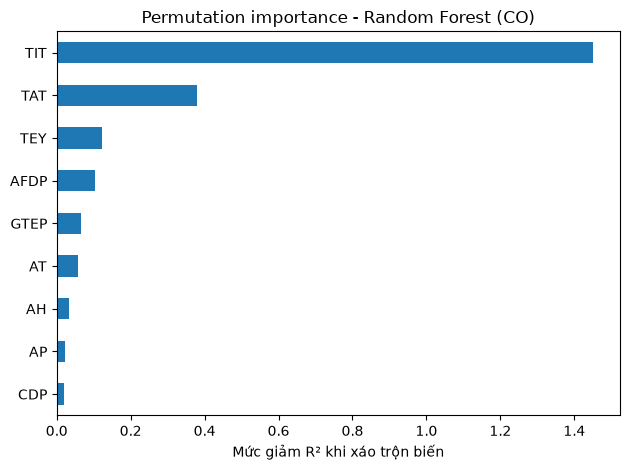

In [9]:
pi = permutation_importance(
    models["Random Forest"],
    X_test,
    y_test,
    n_repeats=5,
    random_state=SEED,
    n_jobs=-1,
)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()
imp.plot.barh(title="Permutation importance - Random Forest (CO)")
plt.xlabel("Mức giảm R² khi xáo trộn biến")
plt.tight_layout()
plt.show()

chia theo thời gian (train 80% đầu, test 20% cuối)

In [10]:
split =int(len(df)*0.8)
Xc_tr, Xc_te=X.iloc[:split],X.iloc[split:]
yc_tr,yc_te = y.iloc[:split],y.iloc[split:]
result_c,_=fit_eval(build_model(),Xc_tr,Xc_te,yc_tr,yc_te)
compare = result[["RMSE","R2"]].join(result_c[["RMSE","R2"]],
                                     lsuffix="_random",rsuffix="_time")
compare.sort_values("RMSE_time").round(4)

,RMSE_random,R2_random,RMSE_time,R2_time
Model,,,,
MLP,1.0690,0.6875,1.2954,0.5567
Random Forest,0.7483,0.8469,1.2979,0.5550
KNN,0.8606,0.7975,1.3161,0.5424
Linear,1.1017,0.6681,1.5262,0.3847
Ridge,1.1017,0.6681,1.5262,0.3846
Naive (mean),1.9125,-0.0001,2.1618,-0.2346


kiểm định wilcoxon trên sai số tuyệt đối

In [11]:
def compare_models(a, b):
    ea = np.abs(y_test.values - preds[a])
    eb = np.abs(y_test.values - preds[b])
    p = wilcoxon(ea, eb).pvalue
    print(f"{a} vs {b}: MAE {ea.mean():.4f} vs {eb.mean():.4f}, p-value = {p:.3g}")

compare_models("Random Forest", "Ridge")
compare_models("Random Forest", "MLP")
compare_models("Random Forest", "KNN")

Random Forest vs Ridge: MAE 0.4403 vs 0.7712, p-value = 0
Random Forest vs MLP: MAE 0.4403 vs 0.7187, p-value = 0
Random Forest vs KNN: MAE 0.4403 vs 0.5285, p-value = 4.69e-75
